# Road frontage vs the land behind it

A ribbon is built roadside with unbuilt land behind it. Every 100 m along QL18, on each
side, this compares two strips:

| strip | distance from the centreline |
|---|---|
| **frontage** | 30–100 m |
| **background** | 500–1500 m, pooled over ~1 km of road |

| frontage | background | class |
|---|---|---|
| high | low | **ribbon** |
| high | high | **built-up** |
| low | any | **open** |
| too few land pixels | | **no frontage** |

Ribbons are runs of ribbon stations at least 200 m long (Verbeek et al. 2014).

In [1]:
from typing import Final

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.ops import substring

from desakota.crs import CRS_UTM
from desakota.frontage import build_reference_line, build_road_pieces
from desakota.landcover import compute_frontage_counts, get_landcover_legend
from desakota.paths import DataLayout
from desakota.stac import create_client, get_collection

STATION_M: Final = 100  # profile unit along the road
PIECE_M: Final = 20  # straight road pieces that pixels are assigned to
PAVEMENT_HALF_WIDTH_M: Final = 12  # road surface left out (LULC maps it as built)
DEPTH_EDGES_M: Final = (0, 30, 60, 100, 150, 250, 500, 1000, 1500, 2000)
FRONTAGE_M: Final = (30, 100)
BACKGROUND_M: Final = (500, 1500)
BACKGROUND_WINDOW_STATIONS: Final = 11  # centred rolling window, ~1.1 km of road
MIN_FRONTAGE_PX: Final = 35  # half the 70 land pixels a full 100 m x 70 m strip holds
FRONTAGE_MIN_FRAC: Final = 0.5  # "high" frontage
BACKGROUND_MAX_FRAC: Final = 0.3  # "low" background
MIN_RIBBON_M: Final = 200  # Verbeek et al. (2014): a ribbon is at least 200 m long
BUILT_AREA_LABEL: Final = 'Built area'
WATER_LABEL: Final = 'Water'
CLASS_COLOURS: Final = {
    'ribbon': '#d62728',
    'built-up': '#525252',
    'open': '#bdbdbd',
    'no frontage': '#ffffff',
}

layout = DataLayout.from_env().ensure()
route_ways = gpd.read_file(layout.processed / 'highways_ql18.gpkg')  # EPSG:32648, from 01
assert route_ways.crs == CRS_UTM
road = route_ways.union_all()
len(route_ways)

809

## 1. Chainage axis

QL18 is mapped as 809 ways: divided sections are two one-way chains, and sections shared
with an expressway are missing from the national tier. `build_reference_line` takes the
shortest path from end to end, with jumps across gaps costing 5× their length. It only
supplies chainage; pixels are assigned to the mapped road (section 2).

reference line: 281.9 km, 277.9 km of it on mapped road, 2820 stations of 100 m


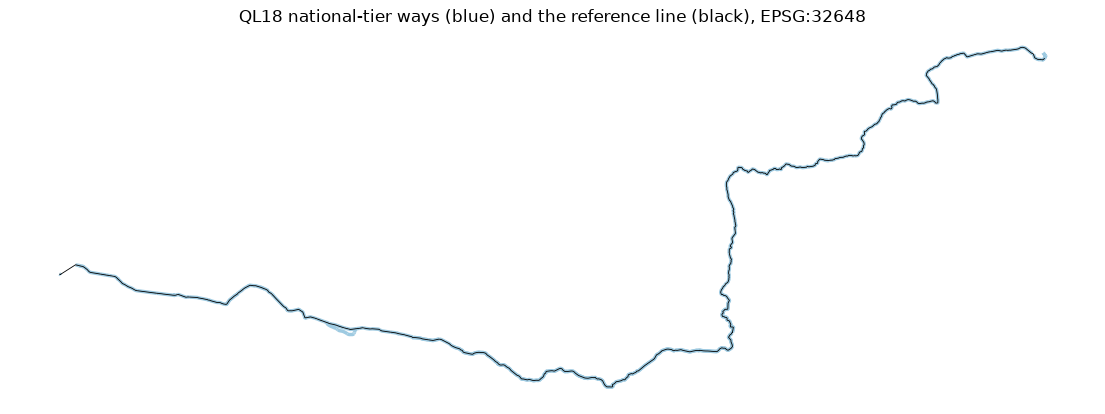

In [2]:
reference = build_reference_line(road, max_gap_m=5_000, gap_penalty=5)
n_stations = int(np.ceil(reference.length / STATION_M))
on_road_km = reference.intersection(road.buffer(1)).length / 1000

ax = route_ways.plot(color='#9ecae1', linewidth=2.5, figsize=(14, 6))
gpd.GeoSeries([reference], crs=CRS_UTM).plot(ax=ax, color='black', linewidth=0.6)
ax.set_title('QL18 national-tier ways (blue) and the reference line (black), EPSG:32648')
ax.set_axis_off()
print(
    f'reference line: {reference.length / 1000:.1f} km, {on_road_km:.1f} km of it on mapped road, '
    f'{n_stations} stations of {STATION_M} m'
)

A divided section: the reference line follows one carriageway. Chainage starts at the
western (Bắc Ninh) end.

Text(0.5, 1.0, 'Divided section: two carriageways (blue), reference line (black)')

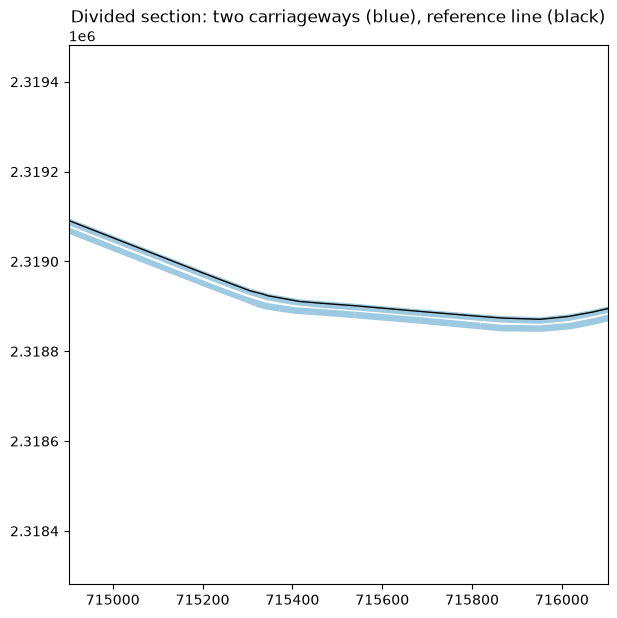

In [3]:
divided = route_ways[route_ways['oneway'] == 'yes']
x, y = divided.geometry.iloc[len(divided) // 2].centroid.coords[0]
fig, ax = plt.subplots(figsize=(7, 7))
route_ways.plot(ax=ax, color='#9ecae1', linewidth=3)
gpd.GeoSeries([reference], crs=CRS_UTM).plot(ax=ax, color='black', linewidth=1)
ax.set_xlim(x - 600, x + 600)
ax.set_ylim(y - 600, y + 600)
ax.set_title('Divided section: two carriageways (blue), reference line (black)')

## 2. Road pieces

Every carriageway is cut into straight pieces of at most 20 m, each with the chainage of
its midpoint and `direction_sign` (+1 along the reference line, −1 against), so opposite
one-way carriageways agree on left and right.

direction_sign
 1    14123
-1     9634
Name: count, dtype: int64

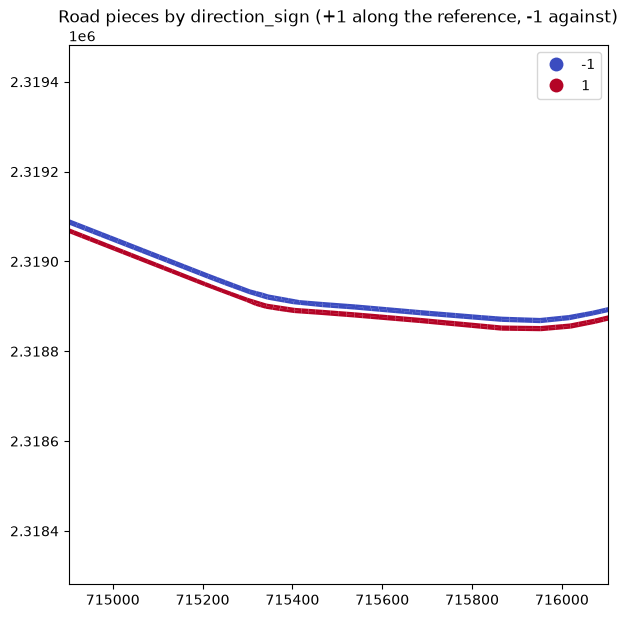

In [4]:
pieces = build_road_pieces(road, reference, piece_m=PIECE_M, station_m=STATION_M).set_crs(CRS_UTM)

fig, ax = plt.subplots(figsize=(7, 7))
pieces.plot(
    ax=ax, column='direction_sign', cmap='coolwarm', categorical=True, legend=True, linewidth=2
)
ax.set_xlim(x - 600, x + 600)
ax.set_ylim(y - 600, y + 600)
ax.set_title('Road pieces by direction_sign (+1 along the reference, -1 against)')
pieces['direction_sign'].value_counts()

## 3. Pixel counts by station, side and distance

Each land pixel within 2 km goes to its nearest road piece, which fixes its station, side
and distance. The road surface (centreline ± 12 m) is excluded; water is excluded from
the denominator. Land cover: 2023, tile 48Q, the clip cached by 04.

In [5]:
lulc_path = layout.raw / 'lulc' / 'lulc_48Q-2023_fa4b43a451f3.tif'  # cached by 04
assert lulc_path.exists(), 'run 04_corridor_width first; it downloads this clip'
legend = get_landcover_legend(get_collection(create_client(), '10M_ANNUAL_LANDUSE'))

counts = compute_frontage_counts(
    pieces,
    lulc_path,
    legend,
    BUILT_AREA_LABEL,
    WATER_LABEL,
    depth_edges_m=DEPTH_EDGES_M,
    exclude=road.buffer(PAVEMENT_HALF_WIDTH_M),
)
counts.head()

,station_id,side,depth_min_m,depth_max_m,n_valid_px,n_built_px
0,0,left,0.0,30.0,25,25
1,0,left,30.0,60.0,52,52
2,0,left,60.0,100.0,69,69
3,0,left,100.0,150.0,104,103
4,0,left,150.0,250.0,346,345


Built share by distance band and side, whole corridor.

side,left,right
depth_max_m,,
30.0,0.890,0.848
60.0,0.831,0.781
100.0,0.754,0.687
150.0,0.659,0.612
250.0,0.583,0.565
500.0,0.488,0.507
1000.0,0.381,0.434
1500.0,0.332,0.410
2000.0,0.274,0.362


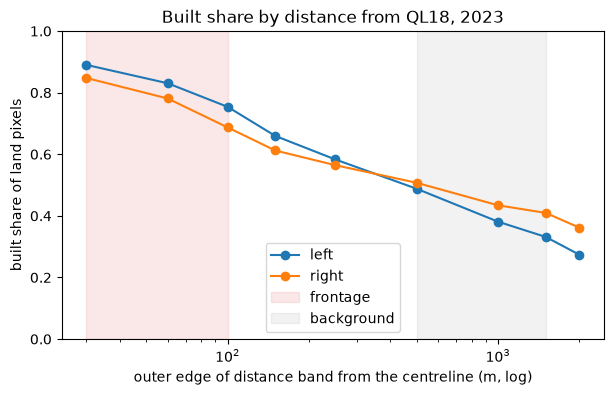

In [6]:
by_band = counts.groupby(['depth_max_m', 'side'])[['n_built_px', 'n_valid_px']].sum()
decay = (by_band['n_built_px'] / by_band['n_valid_px']).unstack('side')
ax = decay.plot(marker='o', figsize=(7, 4), logx=True)
ax.axvspan(*FRONTAGE_M, color=CLASS_COLOURS['ribbon'], alpha=0.1, label='frontage')
ax.axvspan(*BACKGROUND_M, color='grey', alpha=0.1, label='background')
ax.set_xlabel('outer edge of distance band from the centreline (m, log)')
ax.set_ylabel('built share of land pixels')
ax.set_ylim(0, 1)
ax.legend()
ax.set_title('Built share by distance from QL18, 2023')
decay.round(3)

## 4. Frontage and background per station

Counts are pooled before dividing. The background is pooled over a centred window of 11
stations.

In [7]:
def pool_band(lo_m: float, hi_m: float) -> pd.DataFrame:
    """Built and land pixel counts per (station, side), summed over bands inside [lo, hi]."""
    in_band = (counts['depth_min_m'] >= lo_m) & (counts['depth_max_m'] <= hi_m)
    full_index = pd.MultiIndex.from_product(
        [range(n_stations), ['left', 'right']], names=['station_id', 'side']
    )
    pooled = counts[in_band].groupby(['station_id', 'side'])[['n_built_px', 'n_valid_px']].sum()
    return pooled.reindex(full_index, fill_value=0)


frontage = pool_band(*FRONTAGE_M)
background = (
    pool_band(*BACKGROUND_M)
    .groupby(level='side', group_keys=False)
    .apply(lambda side: side.rolling(BACKGROUND_WINDOW_STATIONS, center=True, min_periods=1).sum())
)
stations = pd.DataFrame(
    {
        'chainage_km': frontage.index.get_level_values('station_id') * STATION_M / 1000,
        'n_frontage_px': frontage['n_valid_px'],
        'frontage_built_frac': frontage['n_built_px'] / frontage['n_valid_px'].replace(0, np.nan),
        'background_built_frac': background['n_built_px']
        / background['n_valid_px'].replace(0, np.nan),
    }
)
stations.describe().round(3)

,chainage_km,n_frontage_px,frontage_built_frac,background_built_frac
count,5640.000,5640.000,5513.000,5558.000
mean,140.950,68.512,0.752,0.380
std,81.414,27.338,0.381,0.328
min,0.000,0.000,0.000,0.000
25%,70.475,63.000,0.538,0.069
50%,140.950,69.000,1.000,0.309
75%,211.425,76.000,1.000,0.642
max,281.900,979.000,1.000,1.000


Frontage (red) and background (black) along QL18, per side.

Text(0.5, 0.98, 'Frontage vs background along QL18, 2023 (dashed: class thresholds)')

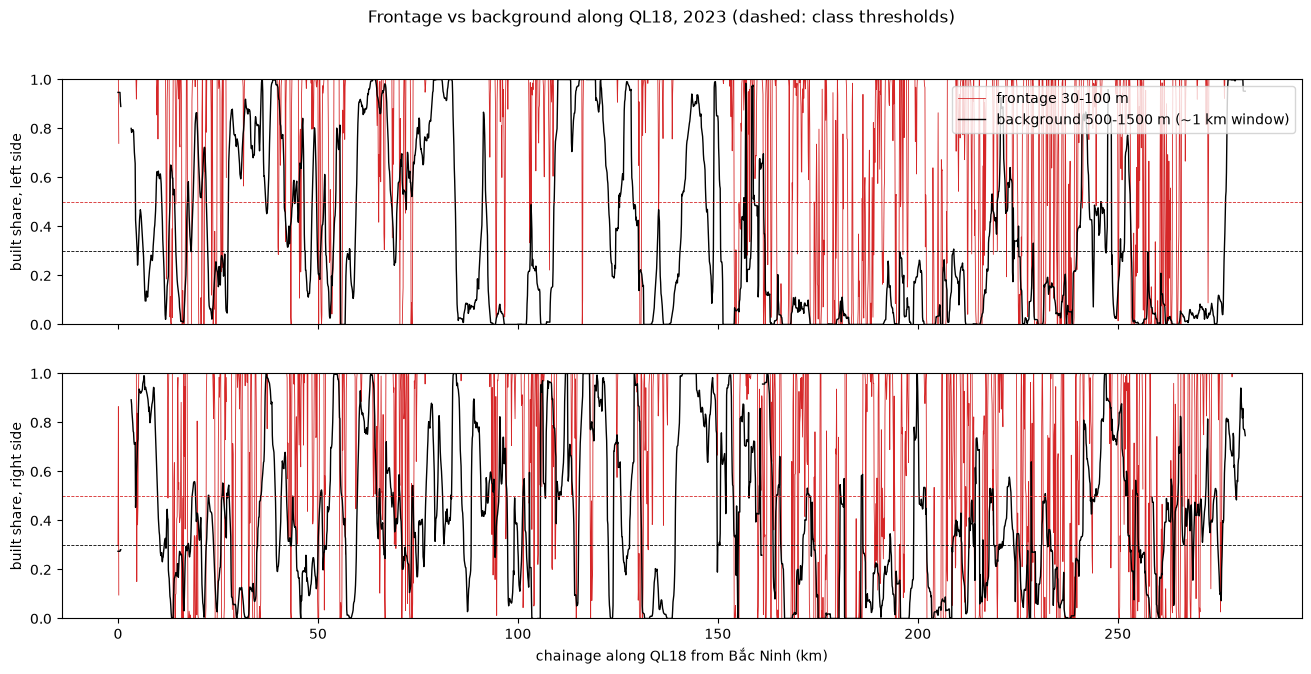

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
for ax, side in zip(axes, ['left', 'right'], strict=True):
    profile = stations.xs(side, level='side')
    ax.plot(
        profile['chainage_km'],
        profile['frontage_built_frac'],
        color='#d62728',
        linewidth=0.6,
        label='frontage 30-100 m',
    )
    ax.plot(
        profile['chainage_km'],
        profile['background_built_frac'],
        color='black',
        linewidth=1,
        label='background 500-1500 m (~1 km window)',
    )
    ax.axhline(FRONTAGE_MIN_FRAC, color='#d62728', linewidth=0.6, linestyle='--')
    ax.axhline(BACKGROUND_MAX_FRAC, color='black', linewidth=0.6, linestyle='--')
    ax.set_ylim(0, 1)
    ax.set_ylabel(f'built share, {side} side')
axes[0].legend(loc='upper right')
axes[1].set_xlabel('chainage along QL18 from Bắc Ninh (km)')
fig.suptitle('Frontage vs background along QL18, 2023 (dashed: class thresholds)')

## 5. Classes and ribbons

In [9]:
def classify(
    stations: pd.DataFrame, frontage_min_frac: float, background_max_frac: float
) -> pd.Series:
    """ribbon / built-up / open / no frontage per station and side."""
    is_high = stations['frontage_built_frac'] >= frontage_min_frac
    return pd.Series(
        np.select(
            [
                stations['n_frontage_px'] < MIN_FRONTAGE_PX,
                is_high & (stations['background_built_frac'] <= background_max_frac),
                is_high,
            ],
            ['no frontage', 'ribbon', 'built-up'],
            'open',
        ),
        index=stations.index,
        name='frontage_class',
    )


def find_ribbons(frontage_class: pd.Series) -> pd.DataFrame:
    """Runs of consecutive ribbon stations per side, at least MIN_RIBBON_M long."""
    runs = []
    for side, classes in frontage_class.groupby(level='side'):
        is_ribbon = classes.droplevel('side').sort_index() == 'ribbon'
        run_id = (is_ribbon != is_ribbon.shift()).cumsum()
        for _, run in is_ribbon[is_ribbon].groupby(run_id[is_ribbon]):
            runs.append({'side': side, 'first_station': run.index.min(), 'n_stations': len(run)})
    ribbons = pd.DataFrame(runs, columns=['side', 'first_station', 'n_stations'])
    ribbons['length_m'] = ribbons['n_stations'] * STATION_M
    ribbons['start_km'] = ribbons['first_station'] * STATION_M / 1000
    return ribbons[ribbons['length_m'] >= MIN_RIBBON_M].reset_index(drop=True)


stations['frontage_class'] = classify(stations, FRONTAGE_MIN_FRAC, BACKGROUND_MAX_FRAC)
ribbons = find_ribbons(stations['frontage_class'])

class_km = stations.groupby(['frontage_class', 'side']).size().unstack('side') * STATION_M / 1000
class_km.round(1).rename_axis('km of frontage by class')

side,left,right
km of frontage by class,,
built-up,109.3,127.4
no frontage,10.1,19.1
open,56.5,71.1
ribbon,106.1,64.4


Classes on the map; each station is offset 300 m to its side.

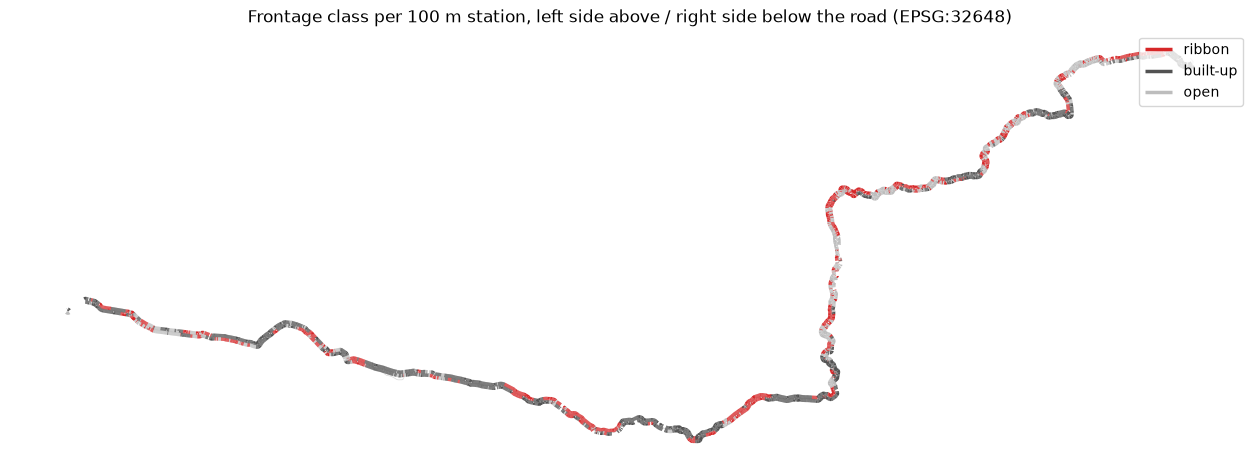

In [10]:
station_lines = [
    substring(reference, i * STATION_M, min((i + 1) * STATION_M, reference.length))
    for i in range(n_stations)
]
offset_m = {'left': 300, 'right': -300}  # shapely: positive offset = left of the line
stations_map = gpd.GeoDataFrame(
    stations.reset_index(),
    geometry=[
        station_lines[station_id].offset_curve(offset_m[side])
        for station_id, side in stations.index
    ],
    crs=CRS_UTM,
)

ax = route_ways.plot(color='#d9d9d9', linewidth=0.5, figsize=(16, 7))
for name, colour in CLASS_COLOURS.items():
    subset = stations_map[stations_map['frontage_class'] == name]
    if name != 'no frontage' and not subset.empty:
        subset.plot(ax=ax, color=colour, linewidth=2.5, label=name)
ax.legend()
ax.set_title(
    'Frontage class per 100 m station, left side above / right side below the road (EPSG:32648)'
)
ax.set_axis_off()

Longest ribbons, with the nearest commune and coordinates.

In [11]:
communes = gpd.read_file(layout.processed / 'communes_ql18_corridor.gpkg')  # EPSG:32648, from 01
ribbon_points = gpd.GeoDataFrame(
    ribbons,
    geometry=[
        station_lines[int(first + n // 2)].interpolate(0.5, normalized=True)
        for first, n in zip(ribbons['first_station'], ribbons['n_stations'], strict=True)
    ],
    crs=CRS_UTM,
)
ribbon_points = ribbon_points.sjoin_nearest(
    communes[['province_name', 'district_name', 'commune_name', 'geometry']], how='left'
).drop(columns='index_right')
lon_lat = ribbon_points.to_crs('EPSG:4326').geometry  # for pasting into a web map
ribbon_points['lat'], ribbon_points['lon'] = lon_lat.y.round(5), lon_lat.x.round(5)
ribbon_points.drop(columns='geometry').sort_values('length_m', ascending=False).head(15)

,side,first_station,n_stations,length_m,start_km,province_name,district_name,commune_name,lat,lon
24,left,969,61,6100,96.9,QuảngNinh,HạLong,ĐạiYên,20.97854,106.92299
20,left,846,60,6000,84.6,QuảngNinh,UôngBí,NamKhê,21.01703,106.81997
100,left,2670,56,5600,267.0,QuảngNinh,MóngCái,HảiĐông,21.53993,107.86898
30,left,1355,51,5100,135.5,QuảngNinh,CẩmPhả,QuangHanh,21.00727,107.22552
25,left,1036,43,4300,103.6,QuảngNinh,HạLong,HàKhẩu,20.95516,106.96979
101,left,2727,40,4000,272.7,QuảngNinh,MóngCái,HảiYên,21.54311,107.91553
29,left,1310,39,3900,131.0,QuảngNinh,CẩmPhả,QuangHanh,20.97966,107.18762
64,left,2091,33,3300,209.1,QuảngNinh,TiênYên,ĐôngHải,21.33579,107.49149
45,left,1700,31,3100,170.0,QuảngNinh,CẩmPhả,CộngHòa,21.14053,107.35291
143,right,1365,29,2900,136.5,QuảngNinh,CẩmPhả,QuangHanh,21.00699,107.22460


## 6. Ribbon length and threshold sensitivity

Ribbon km counts each side separately. The ribboned share is ribbon ÷ (ribbon + open),
i.e. of the frontage that is not built-up.

In [12]:
def summarise(frontage_min_frac: float, background_max_frac: float) -> dict[str, float]:
    classes = classify(stations, frontage_min_frac, background_max_frac)
    runs = find_ribbons(classes)
    ribbon_km = runs['length_m'].sum() / 1000
    rural_km = classes.isin(['ribbon', 'open']).sum() * STATION_M / 1000
    return {
        'ribbon_km': round(ribbon_km, 1),
        'n_ribbons': len(runs),
        'rural_frontage_ribboned_frac': round(ribbon_km / rural_km, 3),
    }


print('chosen thresholds:', summarise(FRONTAGE_MIN_FRAC, BACKGROUND_MAX_FRAC))
sensitivity = pd.DataFrame(
    [
        {'frontage_min_frac': f, 'background_max_frac': b, **summarise(f, b)}
        for f in (0.4, 0.5, 0.6)
        for b in (0.2, 0.3, 0.4)
    ]
)
sensitivity.pivot(index='frontage_min_frac', columns='background_max_frac', values='ribbon_km')

chosen thresholds: {'ribbon_km': np.float64(163.8), 'n_ribbons': 197, 'rural_frontage_ribboned_frac': np.float64(0.549)}


background_max_frac,0.2,0.3,0.4
frontage_min_frac,,,
0.4,131.1,171.6,204.8
0.5,125.1,163.8,195.8
0.6,119.1,156.0,186.2


## 7. Save

One row per station and side; geometry is the station's stretch of reference line.

In [13]:
stem = f'frontage_built_frac_station{STATION_M}m'
stations_out = stations_map.assign(
    geometry=[station_lines[station_id] for station_id in stations_map['station_id']]
)
stations_out.to_file(layout.processed / f'{stem}.gpkg', layer=stem, driver='GPKG')
stem, len(stations_out)

('frontage_built_frac_station100m', 5640)

## Results

With frontage ≥ 0.5 and background ≤ 0.3: 164 km of ribbon in 197 runs, 55% of the
frontage that is not built-up (2023).

- **Frontage is saturated.** The median frontage built share is 1.0, so the class is set
  by the background: ribbon km ranges 125–196 over background thresholds 0.2–0.4, and
  varies by under 10 km over frontage thresholds 0.4–0.6.
- **Left (north) side: 106 km; right: 64 km.** The longest runs (Đại Yên, Nam Khê, Quang
  Hanh) lie where QL18 runs along forested hills, so some may be linear towns against
  hillsides rather than ribbons through farmland.

Next:
1. Check ribbon, built-up and open stations on imagery to calibrate the thresholds and
   test whether the saturated frontage is real.
2. Split the background into crops vs trees/rangeland.
3. Repeat for 2017 to get the trend.
4. Run the same profile on a comparison road.